# External validation: E-MTAB-5061

Independent validation of the pathway-aware T2D beta-cell signal
using the Segerstolpe et al. human pancreatic single-cell dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("..")
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "E-MTAB-5061"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)

print("External validation raw-data folder:")
print(RAW_DIR.resolve())

print("\nExisting files:")
for p in sorted(RAW_DIR.glob("*")):
    print("-", p.name)

External validation raw-data folder:
E:\Project2_Pathway_SingleCell\data\raw\E-MTAB-5061

Existing files:


In [3]:
expr_file = RAW_DIR / "pancreas_refseq_rpkms_counts_3514sc.txt"

with open(expr_file, "r", encoding="utf-8", errors="replace") as f:
    header = f.readline().rstrip("\n").split("\t")

print("Number of header fields:", len(header))

print("\nFirst 10 header fields:")
print(header[:10])

print("\nLast 10 header fields:")
print(header[-10:])

Number of header fields: 3515

First 10 header fields:
['#samples', 'HP1502401_N13', 'HP1502401_D14', 'HP1502401_F14', 'HP1502401_J13', 'HP1502401_B13', 'HP1502401_H13', 'HP1502401_J14', 'HP1502401_B14', 'HP1502401_A14']

Last 10 header fields:
['HP1525301T2D_O10', 'HP1526901T2D_H2', 'HP1526901T2D_I16', 'HP1526901T2D_F7', 'HP1526901T2D_I23', 'HP1525301T2D_K3', 'HP1525301T2D_J10', 'HP1526901T2D_N8', 'HP1526901T2D_O11', 'HP1526901T2D_A8']


In [4]:
# Safely inspect the structure of the first few rows

with open(expr_file, "r", encoding="utf-8", errors="replace") as f:
    for i in range(6):
        line = f.readline().rstrip("\n")
        fields = line.split("\t")

        print(
            f"Line {i + 1}: "
            f"{len(fields)} fields | "
            f"first 5 = {fields[:5]}"
        )

Line 1: 3515 fields | first 5 = ['#samples', 'HP1502401_N13', 'HP1502401_D14', 'HP1502401_F14', 'HP1502401_J13']
Line 2: 7030 fields | first 5 = ['SGIP1', 'NM_032291', '0.0', '0.0', '0.0']
Line 3: 7030 fields | first 5 = ['AZIN2', 'NM_052998+NM_001293562', '0.0', '0.0', '0.0']
Line 4: 7030 fields | first 5 = ['CLIC4', 'NM_013943', '0.0', '0.0', '0.0']
Line 5: 7030 fields | first 5 = ['AGBL4', 'NM_032785', '0.0', '0.0', '0.0']
Line 6: 7030 fields | first 5 = ['NECAP2', 'NM_001145277+NM_001145278+NM_018090', '0.0', '0.0', '0.0']


In [5]:
with open(expr_file, "r", encoding="utf-8", errors="replace") as f:
    for i in range(6):
        fields = f.readline().rstrip("\n").split("\t")
        print(i + 1, len(fields))

1 3515
2 7030
3 7030
4 7030
5 7030
6 7030


In [6]:
# Load only the small SDRF metadata file

sdrf_file = RAW_DIR / "E-MTAB-5061.sdrf.txt"

sdrf = pd.read_csv(
    sdrf_file,
    sep="\t",
    low_memory=False
)

print("Metadata shape:", sdrf.shape)

print("\nMetadata columns:")
for i, col in enumerate(sdrf.columns):
    print(i, col)

Metadata shape: (3514, 49)

Metadata columns:
0 Source Name
1 Characteristics [organism]
2 Characteristics [individual]
3 Characteristics [sex]
4 Characteristics [age]
5 Unit [time unit]
6 Characteristics [body mass index]
7 Characteristics [organism status]
8 Characteristics [clinical information]
9 Characteristics [organism part]
10 Characteristics [cell type]
11 Characteristics [disease]
12 Characteristics [biosource provider]
13 Characteristics [single cell quality]
14 Characteristics [submitted single cell quality]
15 Characteristics [inferred cell type]
16 Comment[ENA_SAMPLE]
17 Comment[BioSD_SAMPLE]
18 Material Type
19 Protocol REF
20 Protocol REF.1
21 Performer
22 Extract Name
23 Comment[single cell isolation]
24 Comment[input molecule]
25 Comment[library construction]
26 Comment[end bias]
27 Comment[primer]
28 Comment[LIBRARY_STRAND]
29 Comment[LIBRARY_LAYOUT]
30 Comment[LIBRARY_SOURCE]
31 Comment[LIBRARY_STRATEGY]
32 Comment[LIBRARY_SELECTION]
33 Comment [INSTRUMENT_MODEL]
34

In [7]:
check_cols = [
    "Characteristics [individual]",
    "Characteristics [cell type]",
    "Characteristics [inferred cell type]",
    "Characteristics [disease]",
    "Factor Value [disease]",
    "FactorValue [single cell identifier] "
]

for col in check_cols:
    print("\n" + "="*80)
    print(col)
    print("="*80)

    if col in sdrf.columns:
        print(sdrf[col].value_counts(dropna=False).head(30))
    else:
        print("Column not found")


Characteristics [individual]
Characteristics [individual]
T2D3    384
T2D4    384
H3      383
H4      383
H5      383
H6      383
T2D1    383
T2D2    383
H2      352
H1       96
Name: count, dtype: int64

Characteristics [cell type]
Characteristics [cell type]
islet of Langerhans    3514
Name: count, dtype: int64

Characteristics [inferred cell type]
Characteristics [inferred cell type]
not applicable                 1305
alpha cell                      886
ductal cell                     386
beta cell                       270
gamma cell                      197
acinar cell                     185
delta cell                      114
PSC cell                         54
unclassified endocrine cell      41
co-expression cell               39
endothelial cell                 16
epsilon cell                      7
mast cell                         7
MHC class II cell                 5
unclassified cell                 2
Name: count, dtype: int64

Characteristics [disease]
Characteristics 

In [8]:
# Find which SDRF metadata column matches the expression-matrix cell names

cell_names = header[1:]

print("Expression cell count:", len(cell_names))
print("First 5 expression cell names:", cell_names[:5])

matches = []

for col in sdrf.columns:
    values = sdrf[col].astype(str)
    overlap = values.isin(cell_names).sum()

    if overlap > 0:
        matches.append((col, overlap))

matches = sorted(matches, key=lambda x: x[1], reverse=True)

print("\nMetadata columns matching expression cell names:")
for col, overlap in matches:
    print(f"{overlap:4d} / {len(cell_names)}  ->  {col}")

Expression cell count: 3514
First 5 expression cell names: ['HP1502401_N13', 'HP1502401_D14', 'HP1502401_F14', 'HP1502401_J13', 'HP1502401_B13']

Metadata columns matching expression cell names:
3514 / 3514  ->  Source Name
3514 / 3514  ->  Extract Name
3514 / 3514  ->  Assay Name
3514 / 3514  ->  FactorValue [single cell identifier] 


In [9]:
# Identify beta cells and align them to expression-matrix columns

meta = sdrf.copy()

beta_meta = meta[
    meta["Characteristics [inferred cell type]"].eq("beta cell")
].copy()

beta_meta = beta_meta.set_index("Source Name")

# Keep beta cells in exactly the same order as the expression matrix
beta_cell_names = [
    cell for cell in cell_names
    if cell in beta_meta.index
]

beta_meta = beta_meta.loc[beta_cell_names]

print("Number of beta cells:", len(beta_cell_names))

print("\nBeta cells by disease:")
print(
    beta_meta["Characteristics [disease]"]
    .value_counts()
)

print("\nBeta cells by donor:")
print(
    beta_meta["Characteristics [individual]"]
    .value_counts()
    .sort_index()
)

print("\nFirst 5 beta cell IDs:")
print(beta_cell_names[:5])

Number of beta cells: 270

Beta cells by disease:
Characteristics [disease]
normal                       171
type II diabetes mellitus     99
Name: count, dtype: int64

Beta cells by donor:
Characteristics [individual]
H1      12
H2      48
H3      32
H4      34
H5      10
H6      35
T2D1    10
T2D2    14
T2D3    11
T2D4    64
Name: count, dtype: int64

First 5 beta cell IDs:
['HP1502401_B14', 'HP1502401_G14', 'HP1502401_D13', 'HP1502401_J22', 'HP1504101T2D_O12']


In [10]:
# Memory-safe loading of RAW COUNTS for beta cells only

# Expression-column position of each beta cell
beta_positions = [
    cell_names.index(cell)
    for cell in beta_cell_names
]

# In each data row:
# field 0 = gene symbol
# field 1 = RefSeq ID
# fields 2 : 2+n_cells = RPKM
# fields 2+n_cells : 2+2*n_cells = raw counts

count_positions = [
    2 + len(cell_names) + pos
    for pos in beta_positions
]

# Count number of genes without loading the file
with open(expr_file, "r", encoding="utf-8", errors="replace") as f:
    n_genes = sum(1 for _ in f) - 1

print("Genes in file:", n_genes)
print("Beta cells to load:", len(beta_cell_names))

# Preallocate a compact numeric matrix
beta_counts_array = np.empty(
    (n_genes, len(beta_cell_names)),
    dtype=np.float64
)

gene_symbols = []

with open(expr_file, "r", encoding="utf-8", errors="replace") as f:
    next(f)  # skip header

    for i, line in enumerate(f):
        fields = line.rstrip("\n").split("\t")

        gene_symbols.append(fields[0])

        beta_counts_array[i, :] = [
            float(fields[j])
            for j in count_positions
        ]

beta_counts = pd.DataFrame(
    beta_counts_array,
    index=gene_symbols,
    columns=beta_cell_names
)

print("\nBeta-cell raw-count matrix shape:")
print(beta_counts.shape)

print("\nFirst 5 genes x first 5 beta cells:")
print(beta_counts.iloc[:5, :5])

print("\nMissing values:")
print(beta_counts.isna().sum().sum())

Genes in file: 26271
Beta cells to load: 270

Beta-cell raw-count matrix shape:
(26271, 270)

First 5 genes x first 5 beta cells:
        HP1502401_B14  HP1502401_G14  HP1502401_D13  HP1502401_J22  \
SGIP1             0.0            0.0            0.0            0.0   
AZIN2             0.0            0.0            1.0          116.0   
CLIC4             0.0            0.0            0.0            1.0   
AGBL4             0.0            5.0            0.0            0.0   
NECAP2           10.0            0.0            4.0            0.0   

        HP1504101T2D_O12  
SGIP1                0.0  
AZIN2                0.0  
CLIC4                0.0  
AGBL4                0.0  
NECAP2               0.0  

Missing values:
0


In [11]:
# Summarize beta cells by donor and disease

beta_summary = (
    beta_meta
    .groupby([
        "Characteristics [individual]",
        "Characteristics [disease]"
    ])
    .size()
    .reset_index(name="N_beta_cells")
)

print(beta_summary.to_string(index=False))

Characteristics [individual] Characteristics [disease]  N_beta_cells
                          H1                    normal            12
                          H2                    normal            48
                          H3                    normal            32
                          H4                    normal            34
                          H5                    normal            10
                          H6                    normal            35
                        T2D1 type II diabetes mellitus            10
                        T2D2 type II diabetes mellitus            14
                        T2D3 type II diabetes mellitus            11
                        T2D4 type II diabetes mellitus            64


In [12]:
# Aggregate beta-cell raw counts to donor-level pseudobulk

beta_donors = beta_meta[
    "Characteristics [individual]"
]

donor_counts = {}

for donor in beta_donors.unique():
    donor_cells = beta_donors[
        beta_donors == donor
    ].index

    donor_counts[donor] = (
        beta_counts[donor_cells]
        .sum(axis=1)
    )

beta_pseudobulk = pd.DataFrame(donor_counts)

print("Pseudobulk matrix shape:")
print(beta_pseudobulk.shape)

print("\nDonors:")
print(beta_pseudobulk.columns.tolist())

Pseudobulk matrix shape:
(26271, 10)

Donors:
['H2', 'T2D1', 'H1', 'T2D2', 'H3', 'H4', 'H5', 'H6', 'T2D4', 'T2D3']


In [13]:
# Donor-level metadata

donor_design = (
    beta_meta[
        [
            "Characteristics [individual]",
            "Characteristics [disease]"
        ]
    ]
    .drop_duplicates()
    .set_index("Characteristics [individual]")
)

donor_design["Condition"] = (
    donor_design["Characteristics [disease]"]
    .map({
        "normal": "ND",
        "type II diabetes mellitus": "T2D"
    })
)

donor_design = donor_design.loc[
    beta_pseudobulk.columns
]

print(donor_design)

print("\nDisease groups:")
print(donor_design["Condition"].value_counts())

      Characteristics [disease] Condition
H2                       normal        ND
T2D1  type II diabetes mellitus       T2D
H1                       normal        ND
T2D2  type II diabetes mellitus       T2D
H3                       normal        ND
H4                       normal        ND
H5                       normal        ND
H6                       normal        ND
T2D4  type II diabetes mellitus       T2D
T2D3  type II diabetes mellitus       T2D

Disease groups:
Condition
ND     6
T2D    4
Name: count, dtype: int64


In [14]:
# Filter low-expression genes in the external pseudobulk cohort
# Same rule as development cohort:
# count >= 10 in at least 5 donors

keep_ext = (beta_pseudobulk >= 10).sum(axis=1) >= 5

external_filtered = beta_pseudobulk.loc[keep_ext].copy()

print("Genes before filtering:", beta_pseudobulk.shape[0])
print("Genes after filtering:", external_filtered.shape[0])

# Library-size normalization to CPM
external_library_sizes = external_filtered.sum(axis=0)

external_cpm = external_filtered.divide(
    external_library_sizes,
    axis=1
) * 1_000_000

# Log2(CPM + 1)
external_log_cpm = np.log2(external_cpm + 1)

print("\nExternal normalized matrix shape:")
print(external_log_cpm.shape)

print("\nCPM library sums:")
print(external_cpm.sum(axis=0).describe())

Genes before filtering: 26271
Genes after filtering: 11781

External normalized matrix shape:
(11781, 10)

CPM library sums:
count    1.000000e+01
mean     1.000000e+06
std      6.721242e-11
min      1.000000e+06
25%      1.000000e+06
50%      1.000000e+06
75%      1.000000e+06
max      1.000000e+06
dtype: float64


In [15]:
import gseapy as gp

# Load the DEVELOPMENT cohort again.
# We use it only to reconstruct the exact pathway definitions
# used when training the pathway model.

train_counts = pd.read_csv(
    PROCESSED_DIR / "beta_counts.csv",
    index_col=0
)

train_design = pd.read_csv(
    PROCESSED_DIR / "beta_design.csv",
    index_col=0
)

# Keep ND and T2D donors only
train_design = train_design[
    train_design["Condition"].isin(["ND", "T2D"])
].copy()

train_counts = train_counts.loc[:, train_design.index]

# Same gene-filtering rule used in Notebook 2
train_keep = (train_counts >= 10).sum(axis=1) >= 5
train_filtered = train_counts.loc[train_keep]

print("Development genes after filtering:", train_filtered.shape[0])

Development genes after filtering: 17408


In [16]:
# Reconstruct the SAME KEGG pathway collection used for training

kegg_sets = gp.get_library(
    name="KEGG_2021_Human",
    organism="human"
)

training_gene_universe = set(
    train_filtered.index.astype(str)
)

filtered_kegg_sets = {}

for pathway, genes in kegg_sets.items():

    overlap = sorted(
        training_gene_universe.intersection(
            {str(g).strip() for g in genes}
        )
    )

    # SAME rule used in Notebook 2
    if 10 <= len(overlap) <= 200:
        filtered_kegg_sets[pathway] = overlap

print("KEGG pathways reconstructed:", len(filtered_kegg_sets))

KEGG pathways reconstructed: 291


In [17]:
external_gene_universe = set(
    external_log_cpm.index.astype(str)
)

common_genes = (
    training_gene_universe
    & external_gene_universe
)

print("Training filtered genes:", len(training_gene_universe))
print("External filtered genes:", len(external_gene_universe))
print("Genes shared by both datasets:", len(common_genes))

# Check how much of each pathway is represented externally
pathway_overlap = []

for pathway, genes in filtered_kegg_sets.items():

    n_training = len(genes)

    external_genes = [
        g for g in genes
        if g in external_gene_universe
    ]

    pathway_overlap.append({
        "Pathway": pathway,
        "Training_genes": n_training,
        "External_genes": len(external_genes),
        "Coverage": len(external_genes) / n_training
    })

pathway_overlap_df = pd.DataFrame(pathway_overlap)

print("\nPathway coverage in external cohort:")
print(
    pathway_overlap_df["Coverage"].describe()
)

print("\nLowest-coverage pathways:")
print(
    pathway_overlap_df
    .sort_values("Coverage")
    .head(10)
    .to_string(index=False)
)

Training filtered genes: 17408
External filtered genes: 11772
Genes shared by both datasets: 10673

Pathway coverage in external cohort:
count    291.000000
mean       0.794809
std        0.124841
min        0.333333
25%        0.748418
50%        0.822430
75%        0.877800
max        1.000000
Name: Coverage, dtype: float64

Lowest-coverage pathways:
                                                      Pathway  Training_genes  External_genes  Coverage
                             Protein digestion and absorption              51              17  0.333333
                              Staphylococcus aureus infection              24               8  0.333333
                                 Systemic lupus erythematosus              23               9  0.391304
                                                      Malaria              20               8  0.400000
                                     ECM-receptor interaction              54              24  0.444444
                 Inte

In [18]:
# Check and collapse duplicated gene symbols BEFORE normalization

print("Pseudobulk rows before collapsing:", beta_pseudobulk.shape[0])
print(
    "Duplicated gene-symbol rows:",
    beta_pseudobulk.index.duplicated().sum()
)

# Sum rows that share the same gene symbol
beta_pseudobulk_gene = (
    beta_pseudobulk
    .groupby(level=0, sort=False)
    .sum()
)

print(
    "Unique genes after collapsing:",
    beta_pseudobulk_gene.shape[0]
)

Pseudobulk rows before collapsing: 26271
Duplicated gene-symbol rows: 745
Unique genes after collapsing: 25526


In [19]:
# Re-filter and normalize after collapsing duplicate gene symbols

keep_ext = (
    (beta_pseudobulk_gene >= 10)
    .sum(axis=1) >= 5
)

external_filtered = (
    beta_pseudobulk_gene
    .loc[keep_ext]
    .copy()
)

external_library_sizes = (
    external_filtered.sum(axis=0)
)

external_cpm = (
    external_filtered
    .divide(external_library_sizes, axis=1)
    * 1_000_000
)

external_log_cpm = np.log2(
    external_cpm + 1
)

print("Genes after corrected filtering:", external_filtered.shape[0])
print("Normalized matrix:", external_log_cpm.shape)
print(
    "Duplicated genes remaining:",
    external_log_cpm.index.duplicated().sum()
)

Genes after corrected filtering: 11774
Normalized matrix: (11774, 10)
Duplicated genes remaining: 0


In [20]:
# Recalculate pathway coverage after duplicate-gene correction

external_gene_universe = set(
    external_log_cpm.index.astype(str)
)

common_genes = (
    training_gene_universe
    & external_gene_universe
)

pathway_overlap = []

for pathway, genes in filtered_kegg_sets.items():

    external_genes = [
        g for g in genes
        if g in external_gene_universe
    ]

    pathway_overlap.append({
        "Pathway": pathway,
        "Training_genes": len(genes),
        "External_genes": len(external_genes),
        "Coverage": len(external_genes) / len(genes)
    })

pathway_overlap_df = pd.DataFrame(pathway_overlap)

print("Training filtered genes:", len(training_gene_universe))
print("External filtered genes:", len(external_gene_universe))
print("Genes shared by both datasets:", len(common_genes))

print("\nCorrected pathway coverage:")
print(pathway_overlap_df["Coverage"].describe())

Training filtered genes: 17408
External filtered genes: 11774
Genes shared by both datasets: 10674

Corrected pathway coverage:
count    291.000000
mean       0.794809
std        0.124841
min        0.333333
25%        0.748418
50%        0.822430
75%        0.877800
max        1.000000
Name: Coverage, dtype: float64


In [21]:
# Create matched pathway definitions using genes available in BOTH studies
# No disease labels are used here.

matched_kegg_sets = {}

for pathway, genes in filtered_kegg_sets.items():

    matched_genes = [
        g for g in genes
        if g in external_gene_universe
    ]

    # Require at least 10 shared genes
    if len(matched_genes) >= 10:
        matched_kegg_sets[pathway] = matched_genes

print("Original training pathways:", len(filtered_kegg_sets))
print("Matched pathways retained:", len(matched_kegg_sets))

matched_sizes = pd.Series({
    pathway: len(genes)
    for pathway, genes in matched_kegg_sets.items()
})

print("\nMatched genes per pathway:")
print(matched_sizes.describe())

Original training pathways: 291
Matched pathways retained: 277

Matched genes per pathway:
count    277.000000
mean      56.444043
std       35.990658
min       10.000000
25%       28.000000
50%       49.000000
75%       81.000000
max      165.000000
dtype: float64


In [22]:
# Normalize the DEVELOPMENT cohort exactly as in Notebook 2

train_library_sizes = train_filtered.sum(axis=0)

train_cpm = (
    train_filtered
    .divide(train_library_sizes, axis=1)
    * 1_000_000
)

train_log_cpm = np.log2(train_cpm + 1)

print("Development normalized matrix:", train_log_cpm.shape)
print("External normalized matrix:", external_log_cpm.shape)

Development normalized matrix: (17408, 34)
External normalized matrix: (11774, 10)


In [23]:
# Calculate matched KEGG pathway scores in BOTH cohorts
# Each pathway uses exactly the same genes in training and external data.

train_pathway_scores = pd.DataFrame(
    index=train_design.index
)

external_pathway_scores = pd.DataFrame(
    index=donor_design.index
)

for pathway, genes in matched_kegg_sets.items():

    train_pathway_scores[pathway] = (
        train_log_cpm
        .loc[genes]
        .mean(axis=0)
        .reindex(train_design.index)
    )

    external_pathway_scores[pathway] = (
        external_log_cpm
        .loc[genes]
        .mean(axis=0)
        .reindex(donor_design.index)
    )

print("Training pathway-score matrix:")
print(train_pathway_scores.shape)

print("\nExternal pathway-score matrix:")
print(external_pathway_scores.shape)

print(
    "\nSame pathway columns:",
    train_pathway_scores.columns.equals(
        external_pathway_scores.columns
    )
)

print(
    "Training missing values:",
    train_pathway_scores.isna().sum().sum()
)

print(
    "External missing values:",
    external_pathway_scores.isna().sum().sum()
)

C:\Users\strangers\AppData\Local\Temp\ipykernel_12108\3581950463.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_pathway_scores[pathway] = (
C:\Users\strangers\AppData\Local\Temp\ipykernel_12108\3581950463.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  external_pathway_scores[pathway] = (


Training pathway-score matrix:
(34, 277)

External pathway-score matrix:
(10, 277)

Same pathway columns: True
Training missing values: 0
External missing values: 0


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Training labels: ND = 0, T2D = 1
y_train = (
    train_design["Condition"]
    .map({"ND": 0, "T2D": 1})
    .astype(int)
)

# External labels: ND = 0, T2D = 1
y_external = (
    donor_design["Condition"]
    .map({"ND": 0, "T2D": 1})
    .astype(int)
)

# Same type of model used in Notebook 2
external_validation_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            solver="liblinear",
            max_iter=5000
        )
    )
])

# Train ONLY on the development cohort
external_validation_model.fit(
    train_pathway_scores,
    y_train
)

# Predict the completely independent external cohort
external_pred = external_validation_model.predict(
    external_pathway_scores
)

external_prob = external_validation_model.predict_proba(
    external_pathway_scores
)[:, 1]

print("External accuracy:",
      accuracy_score(y_external, external_pred))

print("External balanced accuracy:",
      balanced_accuracy_score(y_external, external_pred))

print("External ROC AUC:",
      roc_auc_score(y_external, external_prob))

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_external,
        external_pred
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_external,
        external_pred,
        target_names=["ND", "T2D"],
        digits=3
    )
)

External accuracy: 0.7
External balanced accuracy: 0.625
External ROC AUC: 0.8333333333333334

Confusion matrix:
[[6 0]
 [3 1]]

Classification report:
              precision    recall  f1-score   support

          ND      0.667     1.000     0.800         6
         T2D      1.000     0.250     0.400         4

    accuracy                          0.700        10
   macro avg      0.833     0.625     0.600        10
weighted avg      0.800     0.700     0.640        10



In [25]:
external_predictions = pd.DataFrame({
    "Condition": donor_design["Condition"],
    "True_label": y_external,
    "Predicted_label": external_pred,
    "T2D_probability": external_prob
})

external_predictions["Predicted_condition"] = (
    external_predictions["Predicted_label"]
    .map({0: "ND", 1: "T2D"})
)

print(
    external_predictions
    .sort_values("T2D_probability")
    .to_string()
)

     Condition  True_label  Predicted_label  T2D_probability Predicted_condition
H6          ND           0                0     4.117310e-08                  ND
H5          ND           0                0     5.820741e-08                  ND
T2D1       T2D           1                0     5.871466e-06                  ND
H1          ND           0                0     8.478172e-06                  ND
H3          ND           0                0     4.616100e-05                  ND
H2          ND           0                0     6.764334e-05                  ND
H4          ND           0                0     4.032556e-04                  ND
T2D4       T2D           1                0     6.321628e-04                  ND
T2D3       T2D           1                0     1.397363e-01                  ND
T2D2       T2D           1                1     7.210950e-01                 T2D


In [26]:
# Summarize and save held-out external-validation performance

external_accuracy = accuracy_score(
    y_external,
    external_pred
)

external_balanced_accuracy = balanced_accuracy_score(
    y_external,
    external_pred
)

external_auc = roc_auc_score(
    y_external,
    external_prob
)

external_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "ROC AUC"
    ],
    "Value": [
        external_accuracy,
        external_balanced_accuracy,
        external_auc
    ]
})

print(external_results.to_string(index=False))

print("\nConfusion matrix:")
print(confusion_matrix(y_external, external_pred))

external_results.to_csv(
    TABLES_DIR / "external_validation_metrics.csv",
    index=False
)

external_predictions.to_csv(
    TABLES_DIR / "external_validation_predictions.csv"
)

print("\nSaved external-validation results.")

           Metric    Value
         Accuracy 0.700000
Balanced accuracy 0.625000
          ROC AUC 0.833333

Confusion matrix:
[[6 0]
 [3 1]]


NameError: name 'TABLES_DIR' is not defined

In [27]:
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

In [28]:
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

external_results.to_csv(
    TABLES_DIR / "external_validation_metrics.csv",
    index=False
)

external_predictions.to_csv(
    TABLES_DIR / "external_validation_predictions.csv"
)

print("\nSaved external-validation results.")


Saved external-validation results.


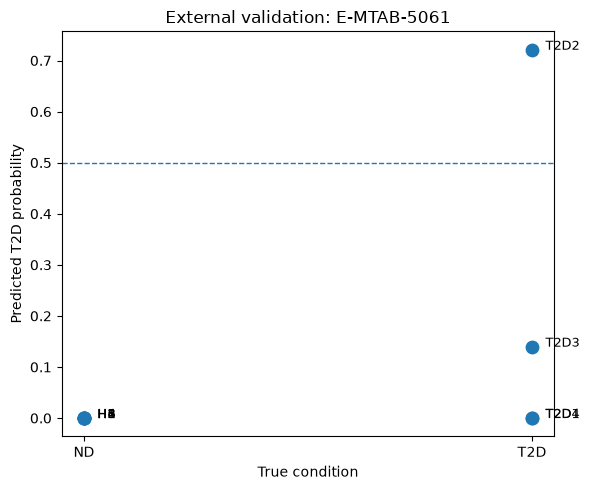

In [29]:
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plot_df = external_predictions.copy()

# Convert condition to x positions
x_map = {"ND": 0, "T2D": 1}
x = plot_df["Condition"].map(x_map)

plt.figure(figsize=(6, 5))

plt.scatter(
    x,
    plot_df["T2D_probability"],
    s=80
)

# Label each donor
for donor, row in plot_df.iterrows():
    plt.text(
        x_map[row["Condition"]] + 0.03,
        row["T2D_probability"],
        donor,
        fontsize=9
    )

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1
)

plt.xticks([0, 1], ["ND", "T2D"])
plt.ylabel("Predicted T2D probability")
plt.xlabel("True condition")
plt.title("External validation: E-MTAB-5061")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "external_validation_probabilities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
print(external_results.to_string(index=False))

           Metric    Value
         Accuracy 0.700000
Balanced accuracy 0.625000
          ROC AUC 0.833333
